<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter7/mechanism_1_sawtooth_bug_explorer_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The 8 Threshold-Switched Jumping Bug motions.

1/2 Simulating Part I of Exercise: The 4 Sub-Threshold Pumping Laws (0 <= u < u_c)...
2/2 Simulating Part II of Exercise: The 4 Super-Threshold Braking Laws (u_c <= u <= 1)...
Done in 8.07 seconds! Displaying both 4-column figures (all 8 motions)...


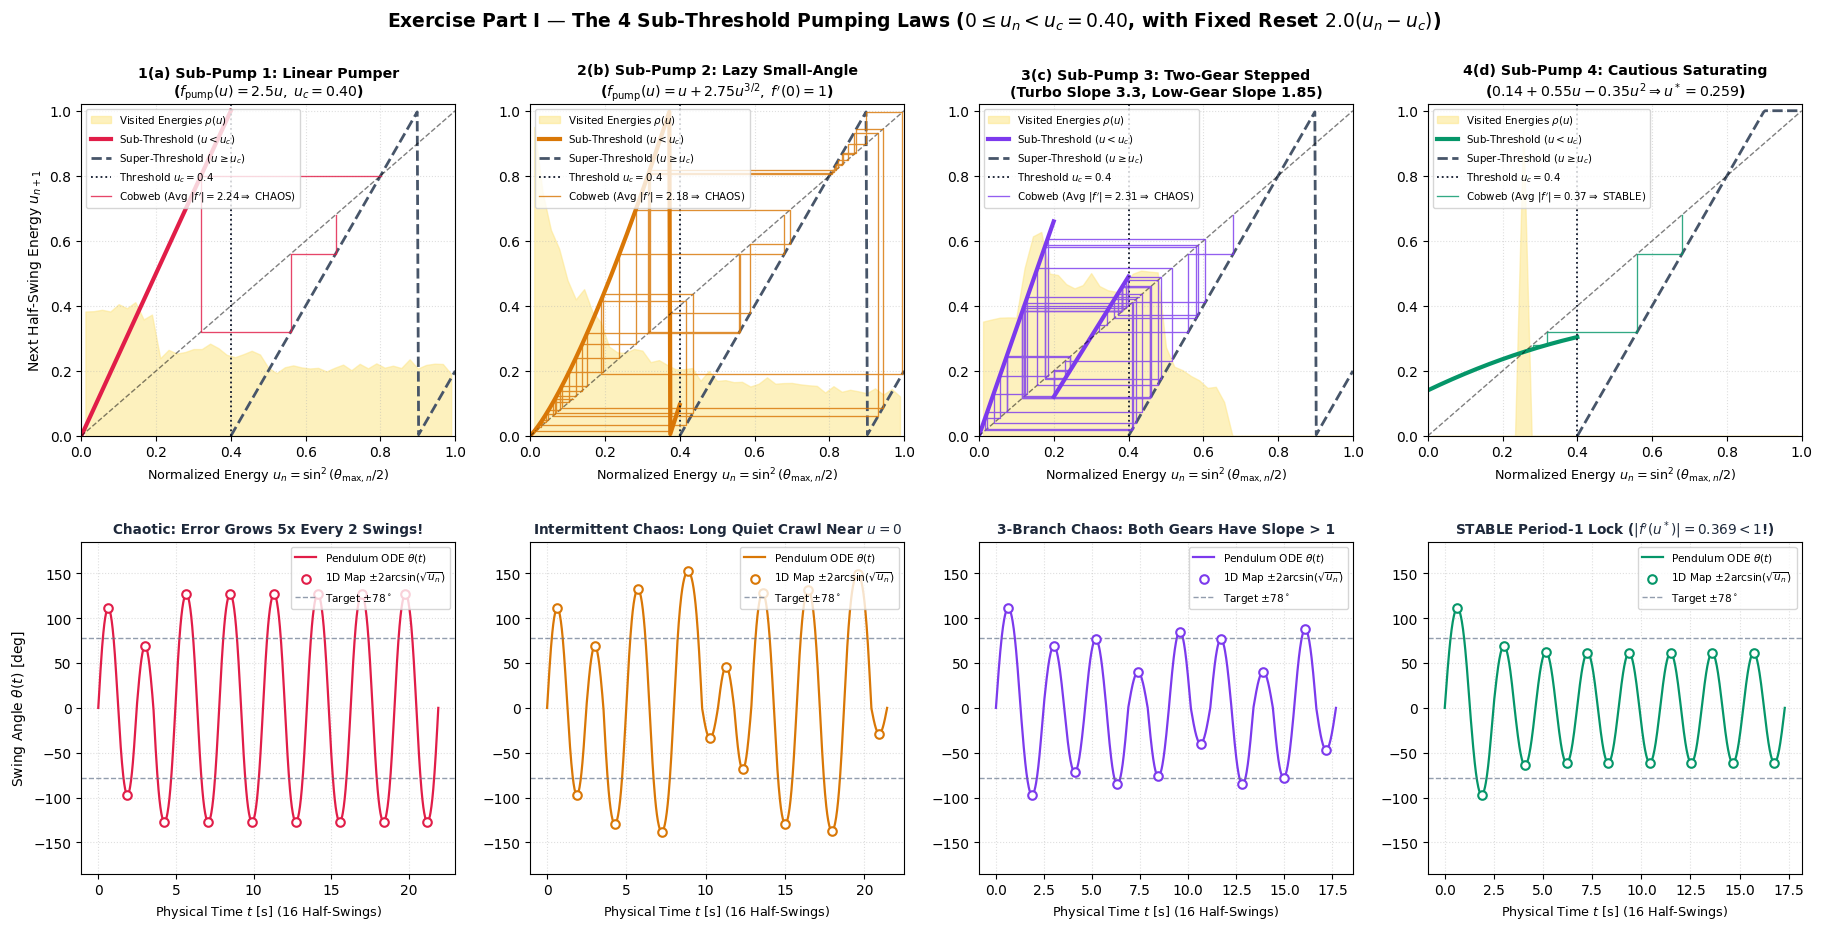

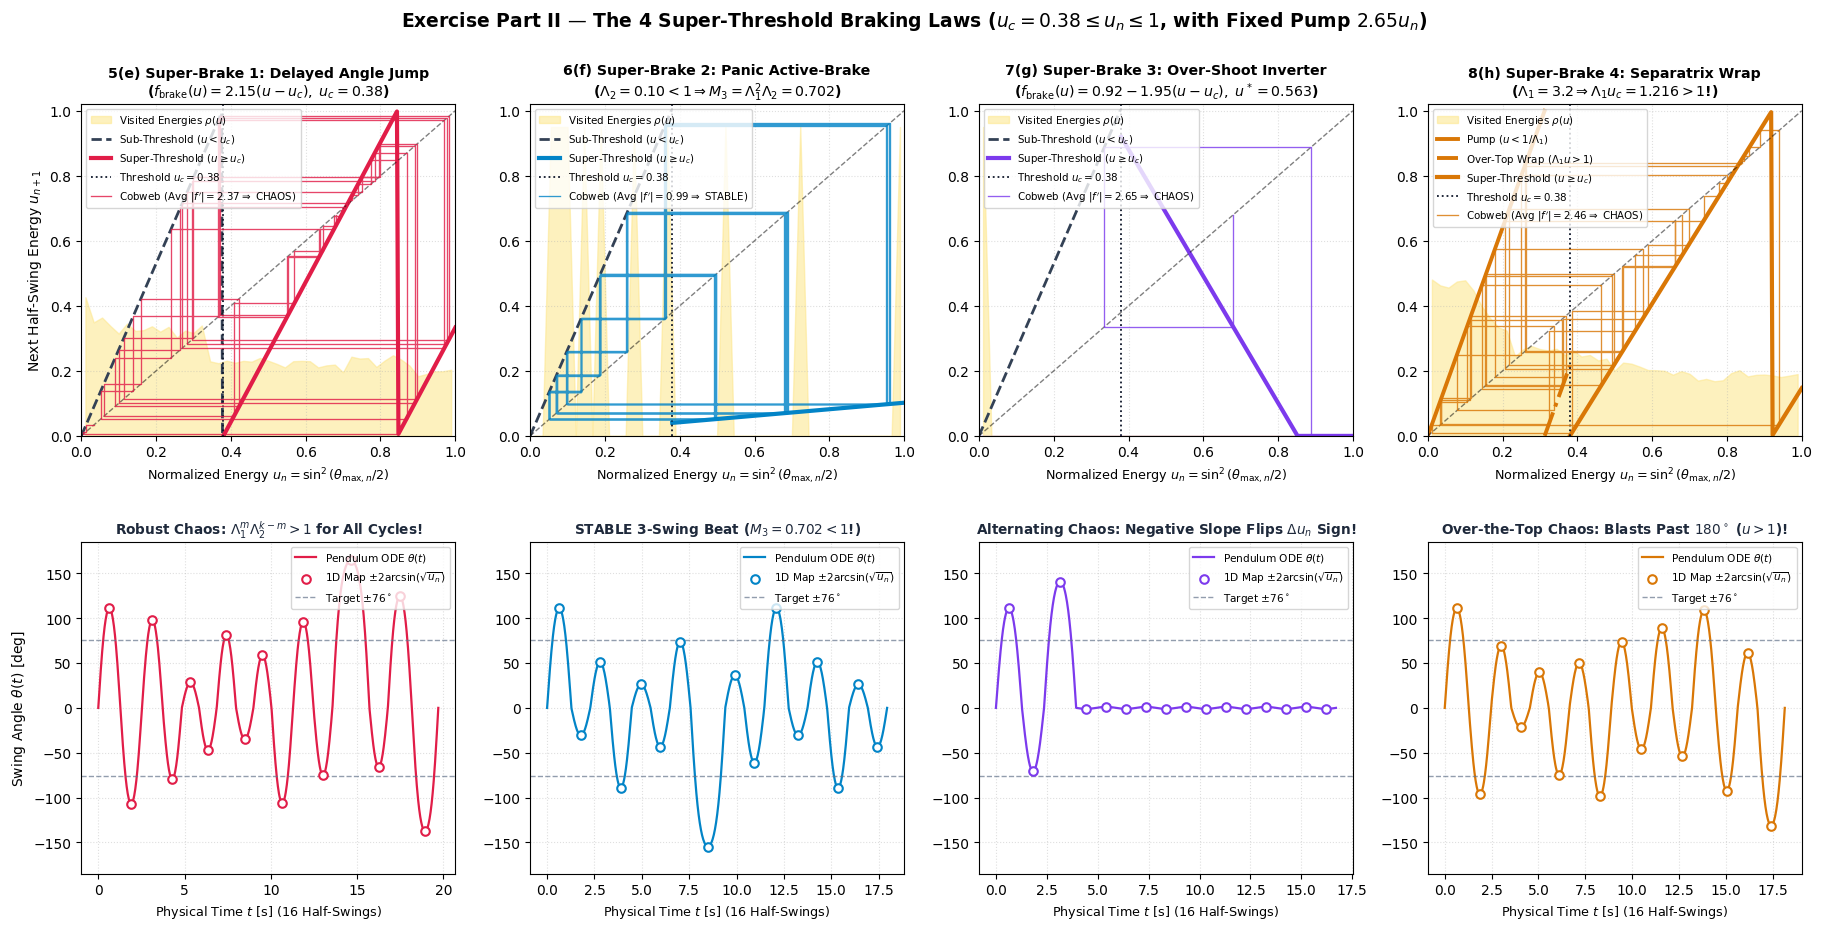

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import time

# =============================================================================
# PART I OF EXERCISE: THE 4 SUB-THRESHOLD PUMPING LAWS (0 <= u_n < u_c)
# (Super-threshold reset branch u >= u_c is fixed to L2 * (u - u_c) with L2=2.0)
# =============================================================================
def sub_pump_1_linear(u, L1=2.50, L2=2.00, uc=0.40):
    """Exercise 1(a): Full-Length Linear Pumper f_pump(u) = 2.5 * u."""
    u_next = np.where(u < uc, L1 * u, L2 * (u - uc))
    slope = np.where(u < uc, L1, L2)
    return np.clip(np.mod(u_next, 1.0), 0.0, 1.0), slope


def sub_pump_2_lazy(u, c_gain=2.75, L2=2.00, uc=0.40):
    """Exercise 2(b): Lazy Small-Angle Pumper f_pump(u) = u + 2.75 * u^(3/2)."""
    u_s = np.maximum(u, 0.0)
    u_next = np.where(u < uc, u_s + c_gain * (u_s ** 1.5), L2 * (u_s - uc))
    slope = np.where(u < uc, 1.0 + 1.5 * c_gain * np.sqrt(u_s), L2)
    return np.clip(np.mod(u_next, 1.0), 0.0, 1.0), slope


def sub_pump_3_two_gear(u, L_turbo=3.30, L_half=1.85, L2=2.00, uc=0.40):
    """Exercise 3(c): Two-Gear Stepped Pumper (Turbo u < uc/2, Low Gear uc/2 <= u < uc)."""
    u_mid = 0.5 * uc
    u_next = np.where(
        u < u_mid,
        L_turbo * u,
        np.where(u < uc, 0.12 + L_half * (u - u_mid), L2 * (u - uc))
    )
    slope = np.where(u < u_mid, L_turbo, np.where(u < uc, L_half, L2))
    return np.clip(np.mod(u_next, 1.0), 0.0, 1.0), slope


def sub_pump_4_cautious(u, u_kick=0.14, L2=2.00, uc=0.40):
    """Exercise 4(d): Cautious Saturating Pumper f_pump(u) = 0.14 + 0.55*u - 0.35*u^2."""
    u_next = np.where(u < uc, u_kick + 0.55 * u - 0.35 * (u ** 2), L2 * (u - uc))
    slope = np.where(u < uc, np.abs(0.55 - 0.70 * u), L2)
    return np.clip(u_next, 0.0, 1.0), slope


# =============================================================================
# PART II OF EXERCISE: THE 4 SUPER-THRESHOLD BRAKING LAWS (u_c <= u_n <= 1)
# (Sub-threshold pumping branch 0 <= u < u_c is fixed to L1 * u with L1=2.65)
# =============================================================================
def super_brake_1_delayed(u, L1=2.65, L2=2.15, uc=0.38):
    """Exercise 5(e): Angle-Sensor Delayed Jump f_brake(u) = L2 * (u - uc) with L2 > 1."""
    u_next = np.where(u < uc, L1 * u, L2 * (u - uc))
    slope = np.where(u < uc, L1, L2)
    return np.clip(np.mod(u_next, 1.0), 0.0, 1.0), slope


def super_brake_2_panic_outward(u, L1=2.65, L2=0.10, uc=0.38):
    """
    Exercise 6(f) & 11(j): Panic Active-Brake at theta = 0 with contracting slope L2 = 0.10 < 1.
     gives 3-swing Chain-Rule multiplier M_3 = L1^2 * L2 = (2.65)^2 * 0.10 = 0.702 < 1 (Stable 3-Cycle!).
    """
    u_next = np.where(u < uc, L1 * u, 0.04 + L2 * (u - uc))
    slope = np.where(u < uc, L1, L2)
    return np.clip(u_next, 0.0, 1.0), slope


def super_brake_3_inverter(u, L1=2.65, L2=-1.95, uc=0.38):
    """Exercise 7(g): Over-Shoot Inverter f_brake(u) = 0.92 - 1.95 * (u - uc) (Negative Slope!)."""
    u_next = np.where(u < uc, L1 * u, 0.92 + L2 * (u - uc))
    slope = np.where(u < uc, L1, np.abs(L2))
    return np.clip(u_next, 0.0, 1.0), slope


def super_brake_4_over_top_wrap(u, L1=3.20, L2=1.85, uc=0.38):
    """
    Exercise 8(h): Over-the-Top Separatrix Wrap (L1 = 3.20 so L1 * uc = 1.216 > 1!).
    Swings in (1/L1, uc) = (0.3125, 0.38) blast over the top (u_next > 1) and wrap mod 1.
    """
    u_raw = np.where(u < uc, L1 * u, L2 * (u - uc))
    slope = np.where(u < uc, L1, L2)
    return np.clip(np.mod(u_raw, 1.0), 0.0, 1.0), slope


# =============================================================================
# HELPER: SIMULATE 1D MAP COBWEB + CONTINUOUS PENDULUM ODE theta(t)
# =============================================================================
def simulate_map_and_pendulum(map_func, u0=0.68, n_cobweb=45, n_long=25000, n_swings_ode=16):
    u_arr = np.zeros(n_long)
    u_arr[0] = u0
    slope_log_sum = 0.0
    for k in range(n_long - 1):
        u_next, sl = map_func(u_arr[k])
        u_arr[k + 1] = float(u_next)
        if k >= 500:
            slope_log_sum += np.log(max(float(sl), 1e-12))

    # Geometric mean slope multiplier per step: M_avg = exp(mean(ln|f'(u)|))
    # M_avg > 1 => Stretching (Chaos!);  M_avg < 1 => Shrinking (Stable Cycle!)
    avg_slope_mult = np.exp(slope_log_sum / (n_long - 501))

    # Cobweb coordinates
    u_cur = u0
    cw_x, cw_y = [u_cur], [u_cur]
    for _ in range(n_cobweb):
        u_n, _ = map_func(u_cur)
        u_n = float(u_n)
        cw_x.extend([u_cur, u_n])
        cw_y.extend([u_n, u_n])
        u_cur = u_n

    # Continuous-time pendulum ODE integration for n_swings_ode half-swings
    w0 = 3.2
    t_all, th_all = [], []
    apex_t, apex_th = [], []
    t_off = 0.0
    sgn = 1.0

    for k in range(n_swings_ode):
        u_k = np.clip(u_arr[k], 1e-4, 0.995)
        th_max = 2.0 * np.arcsin(np.sqrt(u_k))
        om_bot = sgn * 2.0 * w0 * np.sqrt(u_k)

        def hit_bot(t, y):
            return y[0]
        hit_bot.terminal = True
        hit_bot.direction = -sgn

        sol = solve_ivp(
            lambda t, y: [y[1], -(w0**2) * np.sin(y[0])],
            [0.0, 8.0],
            [1e-5 * sgn, om_bot],
            events=hit_bot,
            max_step=0.02,
            rtol=1e-8, atol=1e-8
        )
        t_seg = sol.t + t_off
        t_all.append(t_seg)
        th_all.append(np.degrees(sol.y[0]))
        apex_t.append(t_off + 0.5 * sol.t[-1])
        apex_th.append(sgn * np.degrees(th_max))
        t_off = t_seg[-1]
        sgn *= -1.0

    return (
        u_arr[500:], avg_slope_mult,
        np.array(cw_x), np.array(cw_y),
        np.concatenate(t_all), np.concatenate(th_all),
        np.array(apex_t), np.array(apex_th)
    )


def plot_4_motions_figure(motions_list, fig_title, highlight_sub=True):
    fig, axs = plt.subplots(2, 4, figsize=(18.5, 9.5))
    fig.suptitle(fig_title, fontsize=13.5, fontweight="bold", y=0.98)

    for col, (title_str, m_func, uc_val, color, desc_str, special_split) in enumerate(motions_list):
        (u_long, avg_mult, cw_x, cw_y,
         t_ode, th_ode, ap_t, ap_th) = simulate_map_and_pendulum(m_func)

        ax_top = axs[0, col]
        counts, bins = np.histogram(u_long, bins=45, range=(0.0, 1.0), density=True)
        centers = 0.5 * (bins[:-1] + bins[1:])
        ax_top.fill_between(centers, 0.0, np.minimum(0.26 * counts, 0.95),
                            color="#fde68a", alpha=0.55, label="Visited Energies $\\rho(u)$")

        # Plot Sub-Threshold Branch (0 <= u < uc)
        lw_sub = 3.0 if highlight_sub else 2.0
        col_sub = color if highlight_sub else "#334155"
        ls_sub = "-" if highlight_sub else "--"

        if special_split == "two_gear":
            u_L1 = np.linspace(0.0, 0.5 * uc_val - 1e-4, 80)
            u_L2 = np.linspace(0.5 * uc_val + 1e-4, uc_val - 1e-4, 80)
            ax_top.plot(u_L1, m_func(u_L1)[0], color=col_sub, lw=lw_sub, label="Sub-Threshold ($u < u_c$)")
            ax_top.plot(u_L2, m_func(u_L2)[0], color=col_sub, lw=lw_sub)
        elif special_split == "wrap":
            u_wrap = 1.0 / 3.20
            u_L1 = np.linspace(0.0, u_wrap - 1e-4, 80)
            u_L2 = np.linspace(u_wrap + 1e-4, uc_val - 1e-4, 80)
            ax_top.plot(u_L1, m_func(u_L1)[0], color=color, lw=2.8, label="Pump ($u < 1/\\Lambda_1$)")
            ax_top.plot(u_L2, m_func(u_L2)[0], color=color, lw=2.8, ls="-.", label="Over-Top Wrap ($\\Lambda_1 u > 1$)")
        else:
            u_L = np.linspace(0.0, uc_val - 1e-4, 160)
            ax_top.plot(u_L, m_func(u_L)[0], color=col_sub, lw=lw_sub, ls=ls_sub,
                        label="Sub-Threshold ($u < u_c$)")

        # Plot Super-Threshold Branch (uc <= u <= 1)
        u_R = np.linspace(uc_val + 1e-4, 1.0, 160)
        lw_sup = 2.0 if highlight_sub else 3.0
        col_sup = "#475569" if highlight_sub else color
        ls_sup = "--" if highlight_sub else "-"
        ax_top.plot(u_R, m_func(u_R)[0], color=col_sup, lw=lw_sup, ls=ls_sup,
                    label="Super-Threshold ($u \\geq u_c$)")

        ax_top.axvline(uc_val, color="#0f172a", ls=":", lw=1.3, label=f"Threshold $u_c = {uc_val}$")
        ax_top.plot([0, 1], [0, 1], "k--", lw=1.0, alpha=0.5)

        regime_tag = "CHAOS" if avg_mult > 1.0 else "STABLE"
        ax_top.plot(cw_x, cw_y, color=color, lw=0.95, alpha=0.82,
                    label=f"Cobweb (Avg $|f'|={avg_mult:.2f} \\Rightarrow$ {regime_tag})")

        ax_top.set_title(title_str, fontsize=10.2, fontweight="bold")
        ax_top.set_xlabel("Normalized Energy $u_n = \\sin^2(\\theta_{\\max,n}/2)$", fontsize=9.2)
        if col == 0:
            ax_top.set_ylabel("Next Half-Swing Energy $u_{n+1}$", fontsize=10)
        ax_top.set_xlim(0.0, 1.0)
        ax_top.set_ylim(0.0, 1.02)
        ax_top.grid(True, ls=":", alpha=0.4)
        ax_top.legend(loc="upper left", fontsize=7.4)

        # Bottom Row: Continuous Pendulum Swing theta(t)
        ax_bot = axs[1, col]
        ax_bot.plot(t_ode, th_ode, color=color, lw=1.6, label="Pendulum ODE $\\theta(t)$")
        ax_bot.scatter(ap_t, ap_th, color="white", edgecolor=color, lw=1.5, s=38, zorder=5,
                       label="1D Map $\\pm 2\\arcsin(\\sqrt{u_n})$")

        th_crit_deg = np.degrees(2.0 * np.arcsin(np.sqrt(uc_val)))
        ax_bot.axhline(th_crit_deg, color="#64748b", ls="--", lw=1.0, alpha=0.7,
                       label=f"Target $\\pm {th_crit_deg:.0f}^\\circ$")
        ax_bot.axhline(-th_crit_deg, color="#64748b", ls="--", lw=1.0, alpha=0.7)

        ax_bot.set_title(desc_str, fontsize=9.8, fontweight="bold", color="#1e293b")
        ax_bot.set_xlabel("Physical Time $t$ [s] (16 Half-Swings)", fontsize=9.2)
        if col == 0:
            ax_bot.set_ylabel("Swing Angle $\\theta(t)$ [deg]", fontsize=10)
        ax_bot.set_ylim(-185, 185)
        ax_bot.grid(True, ls=":", alpha=0.4)
        ax_bot.legend(loc="upper right", fontsize=7.6)

    plt.subplots_adjust(left=0.05, right=0.98, bottom=0.07, top=0.88, wspace=0.20, hspace=0.32)


# =============================================================================
# RUN BOTH PART I (4 SUB-PUMPS) AND PART II (4 SUPER-BRAKES)
# =============================================================================
t0 = time.time()
print("1/2 Simulating Part I of Exercise: The 4 Sub-Threshold Pumping Laws (0 <= u < u_c)...")

part1_sub_motions = [
    (
        "1(a) Sub-Pump 1: Linear Pumper\n($f_{\\mathrm{pump}}(u) = 2.5 u,\\; u_c = 0.40$)",
        sub_pump_1_linear, 0.40, "#e11d48",
        "Chaotic: Error Grows 5x Every 2 Swings!", None
    ),
    (
        "2(b) Sub-Pump 2: Lazy Small-Angle\n($f_{\\mathrm{pump}}(u) = u + 2.75 u^{3/2},\\; f'(0)=1$)",
        sub_pump_2_lazy, 0.40, "#d97706",
        "Intermittent Chaos: Long Quiet Crawl Near $u=0$", None
    ),
    (
        "3(c) Sub-Pump 3: Two-Gear Stepped\n(Turbo Slope 3.3, Low-Gear Slope 1.85)",
        sub_pump_3_two_gear, 0.40, "#7c3aed",
        "3-Branch Chaos: Both Gears Have Slope > 1", "two_gear"
    ),
    (
        "4(d) Sub-Pump 4: Cautious Saturating\n($0.14 + 0.55u - 0.35u^2 \\Rightarrow u^*=0.259$)",
        sub_pump_4_cautious, 0.40, "#059669",
        "STABLE Period-1 Lock ($|f'(u^*)| = 0.369 < 1$!)", None
    ),
]

plot_4_motions_figure(
    part1_sub_motions,
    "Exercise Part I — The 4 Sub-Threshold Pumping Laws ($0 \\leq u_n < u_c = 0.40$, with Fixed Reset $2.0(u_n - u_c)$)",
    highlight_sub=True
)

print("2/2 Simulating Part II of Exercise: The 4 Super-Threshold Braking Laws (u_c <= u <= 1)...")

part2_super_motions = [
    (
        "5(e) Super-Brake 1: Delayed Angle Jump\n($f_{\\mathrm{brake}}(u) = 2.15(u - u_c),\\; u_c=0.38$)",
        super_brake_1_delayed, 0.38, "#e11d48",
        "Robust Chaos: $\\Lambda_1^m \\Lambda_2^{k-m} > 1$ for All Cycles!", None
    ),
    (
        "6(f) Super-Brake 2: Panic Active-Brake\n($\\Lambda_2 = 0.10 < 1 \\Rightarrow M_3 = \\Lambda_1^2 \\Lambda_2 = 0.702$)",
        super_brake_2_panic_outward, 0.38, "#0284c7",
        "STABLE 3-Swing Beat ($M_3 = 0.702 < 1$!)", None
    ),
    (
        "7(g) Super-Brake 3: Over-Shoot Inverter\n($f_{\\mathrm{brake}}(u) = 0.92 - 1.95(u - u_c),\\; u^*=0.563$)",
        super_brake_3_inverter, 0.38, "#7c3aed",
        "Alternating Chaos: Negative Slope Flips $\\Delta u_n$ Sign!", None
    ),
    (
        "8(h) Super-Brake 4: Separatrix Wrap\n($\\Lambda_1 = 3.2 \\Rightarrow \\Lambda_1 u_c = 1.216 > 1$!)",
        super_brake_4_over_top_wrap, 0.38, "#d97706",
        "Over-the-Top Chaos: Blasts Past $180^\\circ$ ($u > 1$)!", "wrap"
    ),
]

plot_4_motions_figure(
    part2_super_motions,
    "Exercise Part II — The 4 Super-Threshold Braking Laws ($u_c = 0.38 \\leq u_n \\leq 1$, with Fixed Pump $2.65 u_n$)",
    highlight_sub=False
)

print(f"Done in {time.time() - t0:.2f} seconds! Displaying both 4-column figures (all 8 motions)...")
plt.show()